In [3]:
!pip install shap scikit-learn pandas numpy matplotlib

Dataset:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0  

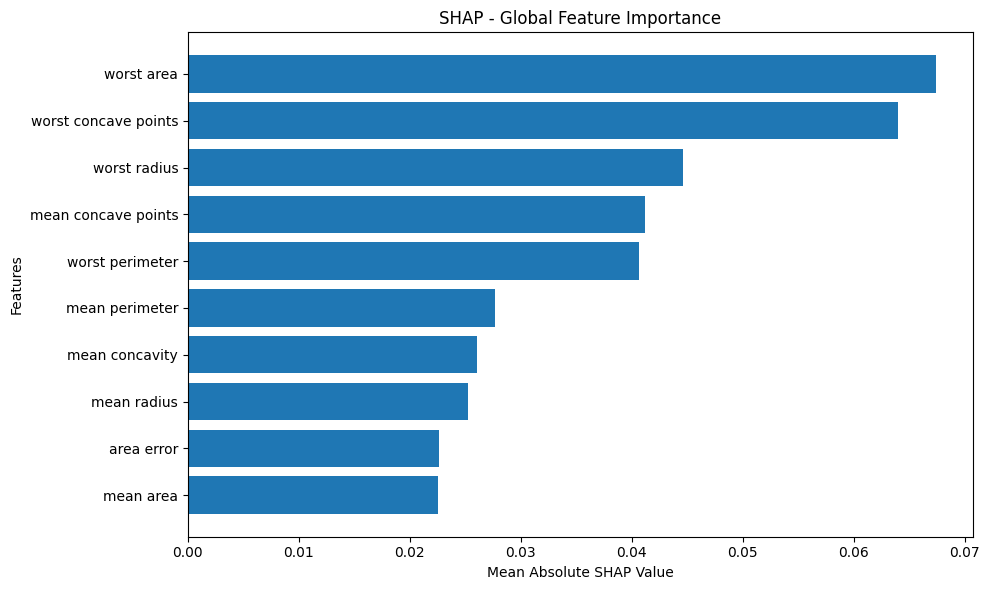

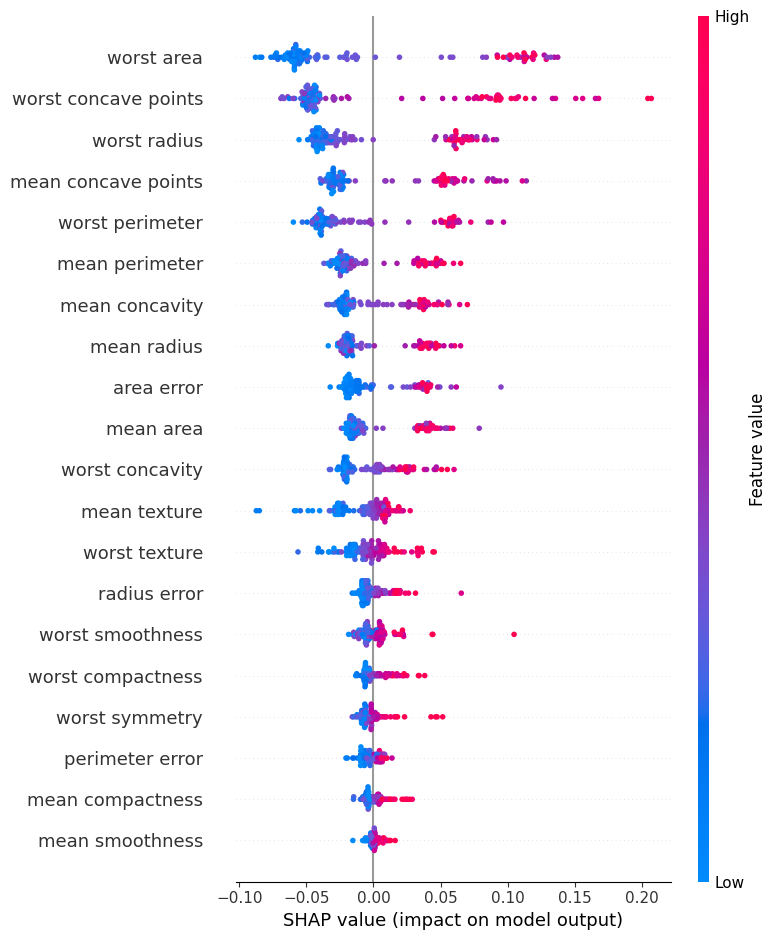


TEST INSTANCE 1
Actual Class: Benign
Predicted Class: Benign
Malignant Probability: 1.0 %

Top 5 Important Features:
             Feature  Feature Value  SHAP Value
          worst area      510.50000   -0.056537
worst concave points        0.08958   -0.039630
     worst perimeter       83.74000   -0.038022
        worst radius       12.82000   -0.034449
        mean texture       10.82000   -0.028488


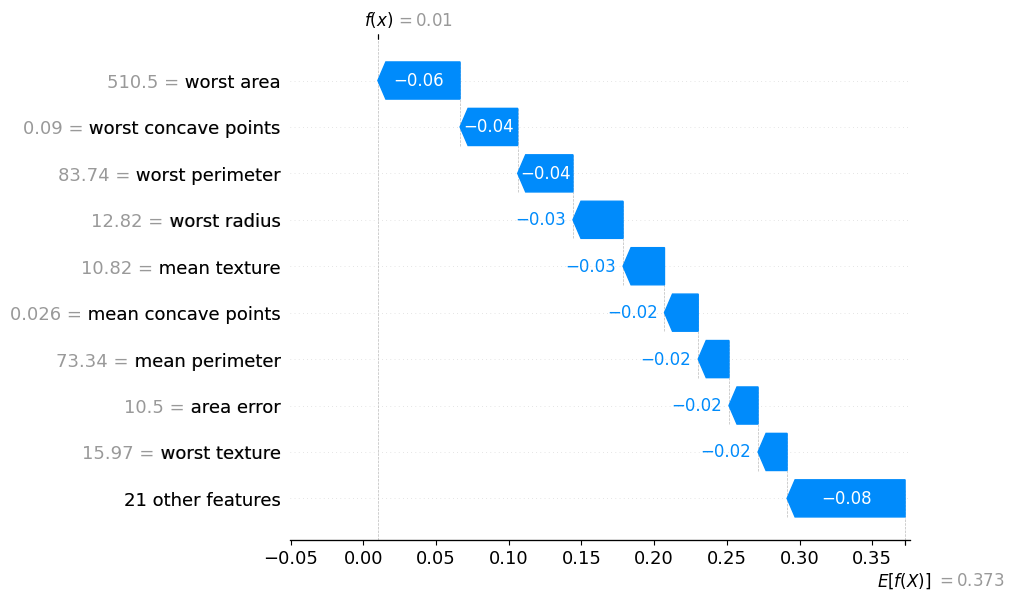


TEST INSTANCE 2
Actual Class: Malignant
Predicted Class: Malignant
Malignant Probability: 100.0 %

Top 5 Important Features:
             Feature  Feature Value  SHAP Value
          worst area      2010.0000    0.112081
worst concave points         0.2105    0.084175
        worst radius        25.5800    0.064477
     worst perimeter       165.3000    0.056472
 mean concave points         0.1310    0.051972


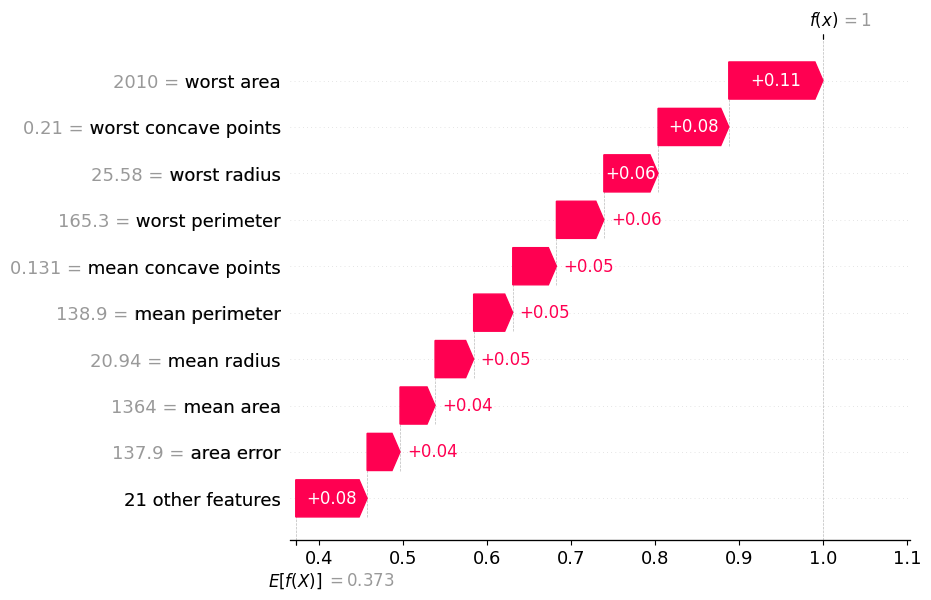


FEATURE IMPORTANCE COMPARISON:
             Feature  Instance 1  Instance 2  Average Importance
          worst area    0.056537    0.112081            0.084309
worst concave points    0.039630    0.084175            0.061903
        worst radius    0.034449    0.064477            0.049463
     worst perimeter    0.038022    0.056472            0.047247
 mean concave points    0.023196    0.051972            0.037584
      mean perimeter    0.021168    0.046513            0.033841
         mean radius    0.017853    0.045926            0.031889
          area error    0.019997    0.039149            0.029573
      mean concavity    0.018044    0.034900            0.026472
           mean area    0.009733    0.041692            0.025713


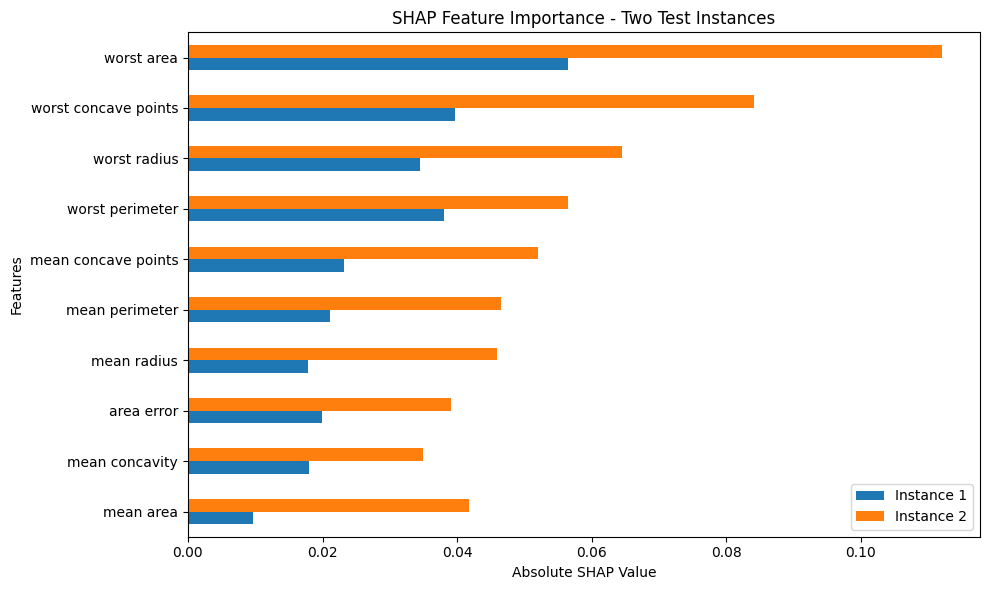

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Load Dataset
data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# 1 = Malignant, 0 = Benign
y = (data.target == 0).astype(int)

print("Dataset:")
print(X.head())

print("\nDataset Shape:", X.shape)

print("\nClass Distribution:")
print(
    pd.Series(y).value_counts().rename({
        0: 'Benign',
        1: 'Malignant'
    })
)

# 2. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# 3. Train Random Forest Model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("\nRandom Forest Model Trained Successfully")

# 4. Predict Test Data
y_pred = model.predict(X_test)

# 5. Evaluate Model
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Benign', 'Malignant']
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 6. Initialize SHAP Explainer
explainer = shap.TreeExplainer(model)

raw_shap_values = explainer.shap_values(X_test)

# 7. Extract SHAP Values for Malignant Class
def get_positive_shap(values):

    if isinstance(values, list):
        return np.asarray(values[1])

    values = np.asarray(values)

    if values.ndim == 3:
        if values.shape[-1] == 2:
            return values[:, :, 1]
        elif values.shape[1] == 2:
            return values[:, 1, :]

    return values

shap_values = get_positive_shap(raw_shap_values)

# 8. Global Feature Importance
importance = np.abs(shap_values).mean(axis=0)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nGLOBAL FEATURE IMPORTANCE:")
print(feature_importance.head(10).to_string(index=False))

# 9. Visualize Global Feature Importance
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(10).sort_values(
    by='Importance'
)

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title("SHAP - Global Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

# 10. SHAP Summary Plot
shap.summary_plot(
    shap_values,
    X_test
)


# 11. Select Two Test Instances
X_two = X_test.iloc[:2]
y_two = y_test[:2]

shap_two = shap_values[:2]

# 12. Get Base Value
base = np.asarray(explainer.expected_value)

if base.ndim == 0:
    base_value = float(base)
else:
    base_value = float(base.reshape(-1)[1])

# 13. Create SHAP Explanation Object
explanation = shap.Explanation(
    values=shap_two,
    base_values=np.full(2, base_value),
    data=X_two.values,
    feature_names=X.columns.tolist()
)

# 14. Analyze Two Test Instances
for i in range(2):

    prediction = model.predict(X_two.iloc[[i]])[0]

    probability = model.predict_proba(
        X_two.iloc[[i]]
    )[0][1]

    print("\n================================")
    print("TEST INSTANCE", i + 1)
    print("================================")

    print(
        "Actual Class:",
        "Malignant" if y_two[i] == 1 else "Benign"
    )

    print(
        "Predicted Class:",
        "Malignant" if prediction == 1 else "Benign"
    )

    print(
        "Malignant Probability:",
        round(probability * 100, 2), "%"
    )

    # Calculate Individual Feature Contributions
    contributions = pd.DataFrame({
        'Feature': X.columns,
        'Feature Value': X_two.iloc[i].values,
        'SHAP Value': shap_two[i]
    })

    contributions['Absolute SHAP'] = np.abs(
        contributions['SHAP Value']
    )

    contributions = contributions.sort_values(
        by='Absolute SHAP',
        ascending=False
    )

    print("\nTop 5 Important Features:")
    print(
        contributions[
            ['Feature', 'Feature Value', 'SHAP Value']
        ].head(5).to_string(index=False)
    )

    # Individual SHAP Waterfall Plot
    shap.plots.waterfall(
        explanation[i],
        max_display=10
    )

# 15. Compare Two Test Instances
comparison = pd.DataFrame({
    'Feature': X.columns,
    'Instance 1': np.abs(shap_two[0]),
    'Instance 2': np.abs(shap_two[1])
})

comparison['Average Importance'] = (
    comparison['Instance 1'] +
    comparison['Instance 2']
) / 2

comparison = comparison.sort_values(
    by='Average Importance',
    ascending=False
)

print("\nFEATURE IMPORTANCE COMPARISON:")
print(comparison.head(10).to_string(index=False))

# 16. Visualize Comparison
top_comparison = comparison.head(10).sort_values(
    by='Average Importance'
)

top_comparison.plot(
    x='Feature',
    y=['Instance 1', 'Instance 2'],
    kind='barh',
    figsize=(10, 6)
)

plt.title("SHAP Feature Importance - Two Test Instances")
plt.xlabel("Absolute SHAP Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()
